#  Lab 1 
### Part 1: Regression

In [2]:
import pandas as pd
path = "/kaggle/input/datasets/dgawlik/nyse/"
prices = pd.read_csv(path + "prices-split-adjusted.csv")

print(prices.shape)
prices.head()


(851264, 7)


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [3]:
prices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    851264 non-null  object 
 1   symbol  851264 non-null  object 
 2   open    851264 non-null  float64
 3   close   851264 non-null  float64
 4   low     851264 non-null  float64
 5   high    851264 non-null  float64
 6   volume  851264 non-null  float64
dtypes: float64(5), object(2)
memory usage: 45.5+ MB


In [4]:
# convertir la date pour ne pas avoir un problème
prices["date"] = pd.to_datetime(prices["date"])
prices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB


In [5]:
# période couverte
print(prices["date"].min(), prices["date"].max())
# nombre d'entreprises
print(prices["symbol"].nunique())

2010-01-04 00:00:00 2016-12-30 00:00:00
501


In [6]:
prices.describe()

,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294037760,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


on remarque d'après les résultats de describe() que par exemple les colonnes close et volume sont sur des échelles très différentes (un prix close se compte en dizaines alors que un volume est en millions) -> C’est pour ça qu’on normalisera (ou standardisera) les données avant l’entraînement.


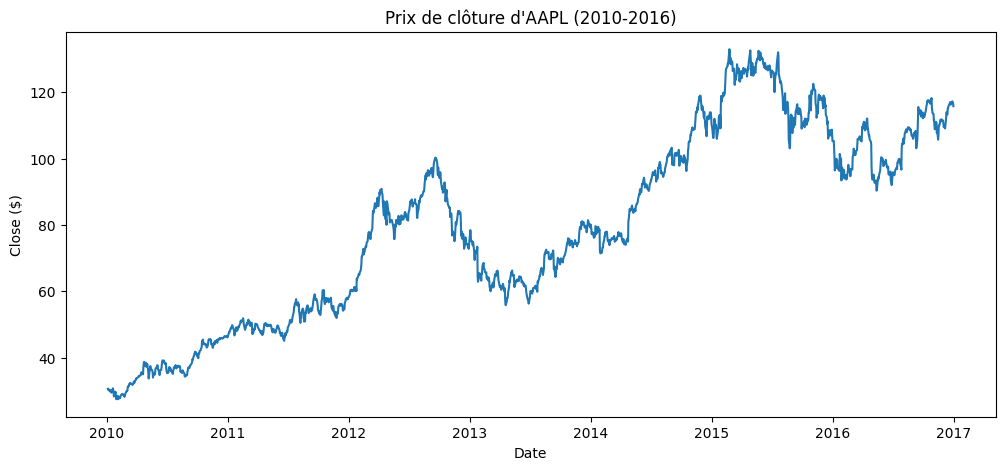

In [7]:
# on visualise une série temporelle (pour voir vraiment la dynamique des prix)
import matplotlib.pyplot as plt

aapl = prices[prices["symbol"] == "AAPL"]

plt.figure(figsize=(12, 5))
plt.plot(aapl["date"], aapl["close"])
plt.title("Prix de clôture d'AAPL (2010-2016)")
plt.xlabel("Date")
plt.ylabel("Close ($)")
plt.show()

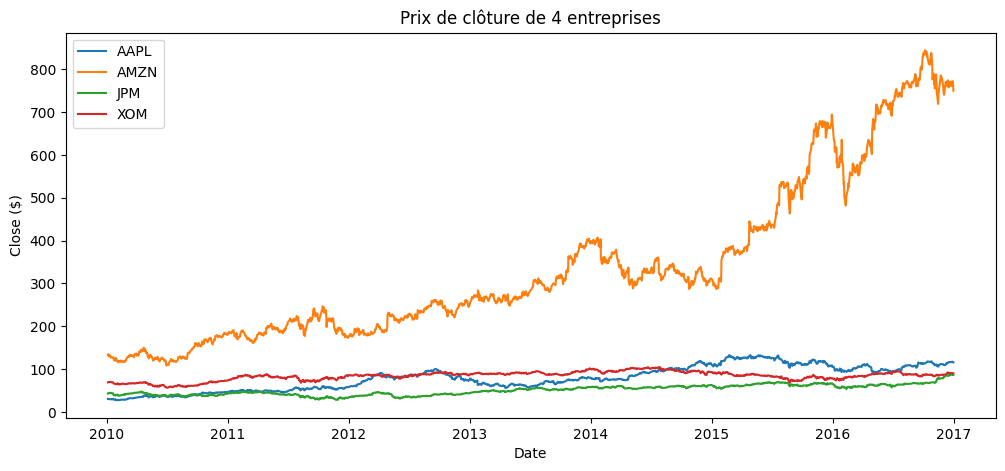

In [8]:
# comparons plusieurs entreprises 
symbols = ["AAPL", "AMZN", "JPM", "XOM"]

plt.figure(figsize=(12, 5))
for s in symbols:
    sub = prices[prices["symbol"] == s]
    plt.plot(sub["date"], sub["close"], label=s)

plt.title("Prix de clôture de 4 entreprises")
plt.xlabel("Date")
plt.ylabel("Close ($)")
plt.legend()
plt.show()

**Interprétation :**
- Les niveaux de prix diffèrent fortement d'une entreprise à l'autre : AMZN passe d'environ 130 $ à plus de 750 $, alors qu'AAPL, JPM et XOM restent entre 30 et 130 $.
- Les dynamiques sont aussi différentes : AMZN a une forte croissance, JPM une hausse lente, XOM est presque stable.
- Chaque entreprise est une série temporelle distincte, avec sa propre échelle et sa propre tendance. Mélanger les 501 entreprises dans un seul modèle risque donc de compliquer l'apprentissage.
- Conséquence pour la suite de mon travail: il faudra soit travailler sur une seule entreprise, soit normaliser les données avec soin.

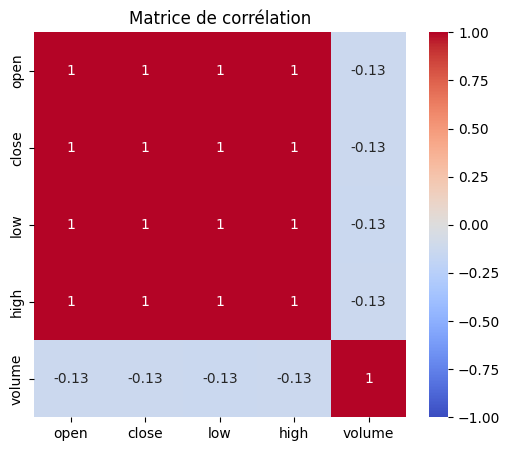

In [9]:
# les corrélations
import seaborn as sns

cols = ["open", "close", "low", "high", "volume"]
corr = prices[cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.show()

**Interprétation :**
- `open`, `high`, `low` et `close` sont quasi parfaitement corrélées (≈ 1) : elles contiennent presque la même information.
- Prédire `close` à partir des autres prix du même jour serait trop facile (fuite d'information), il faudra donc définir la tâche autrement.
- `volume` est faiblement corrélé aux prix (-0,13) : il apporte une information différente.
- Cette corrélation est calculée sur toutes les entreprises mélangées, il faut l'interpréter avec prudence.

In [10]:
# propreté des données
print("Lignes avec volume = 0 :", (prices["volume"] == 0).sum())
print("Doublons :", prices.duplicated().sum())

Lignes avec volume = 0 : 21
Doublons : 0



**Doublons : 0. Aucune ligne n’est répétée, rien à nettoyer de ce côté.**
**volume = 0 : 21 lignes sur 851 264, soit environ 0,0025 %. C’est négligeable.**


In [11]:
prices[prices["volume"] == 0]
prices[prices["volume"] == 0]["symbol"].value_counts()

symbol
CHTR    18
VRTX     1
CB       1
SNI      1
Name: count, dtype: int64

In [12]:
prices[prices["symbol"] == "CHTR"].query("volume == 0")

,date,symbol,open,close,low,high,volume
1270,2010-01-06,CHTR,35.000000,35.000000,35.000000,35.000000,0.0
13906,2010-02-16,CHTR,29.740000,29.740000,29.740000,29.740000,0.0
14374,2010-02-17,CHTR,29.740000,29.740000,29.740000,29.740000,0.0
15310,2010-02-19,CHTR,29.700001,29.700001,29.700001,29.700001,0.0
16246,2010-02-23,CHTR,29.700001,29.700001,29.700001,29.700001,0.0
16714,2010-02-24,CHTR,29.700001,29.700001,29.700001,29.700001,0.0
30754,2010-04-08,CHTR,34.549999,34.549999,34.549999,34.549999,0.0
32158,2010-04-13,CHTR,35.000000,35.000000,35.000000,35.000000,0.0
34498,2010-04-20,CHTR,36.009998,36.009998,36.009998,36.009998,0.0
42465,2010-05-13,CHTR,38.000000,38.000000,38.000000,38.000000,0.0


In [13]:
prices_clean = prices[prices["volume"] > 0].copy()
print(prices.shape, prices_clean.shape)

(851264, 7) (851243, 7)


**Nettoyage :**
- Aucun doublon, aucune valeur manquante.
- 21 lignes ont `volume = 0` (dont 18 pour CHTR en 2010), avec open = high = low = close : aucune transaction ce jour-là, le prix n'est que le dernier prix connu.
- Ces lignes ne contiennent pas d'information de marché utile ; comme elles sont très peu nombreuses (≈ 0,0025 %), on les supprime.

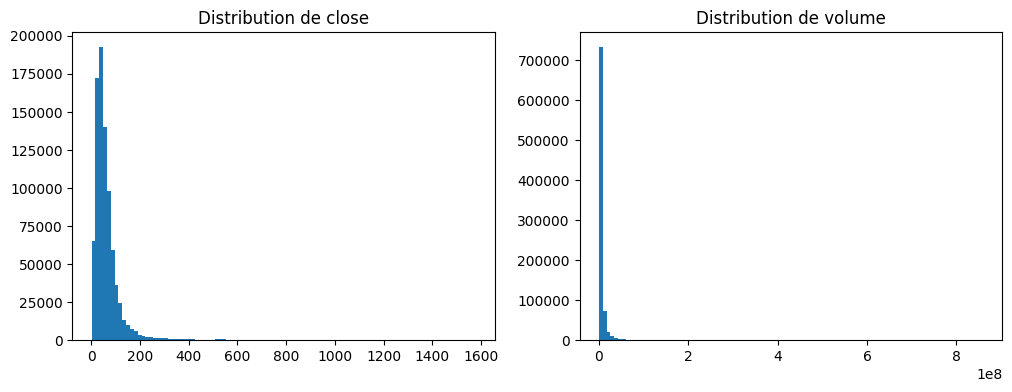

In [14]:
# les distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(prices_clean["close"], bins=100)
axes[0].set_title("Distribution de close")

axes[1].hist(prices_clean["volume"], bins=100)
axes[1].set_title("Distribution de volume")

plt.show()

**Interprétation :**
- `close` et `volume` sont fortement asymétriques à droite : la majorité des valeurs est faible, avec une longue queue de valeurs extrêmes (close jusqu'à ~1600 $, volume jusqu'à ~850 millions).
- `volume` est particulièrement concentré près de 0, avec quelques pics exceptionnels.
- Ces valeurs extrêmes peuvent déstabiliser l'entraînement : une transformation logarithmique avant la normalisation sera à tester.

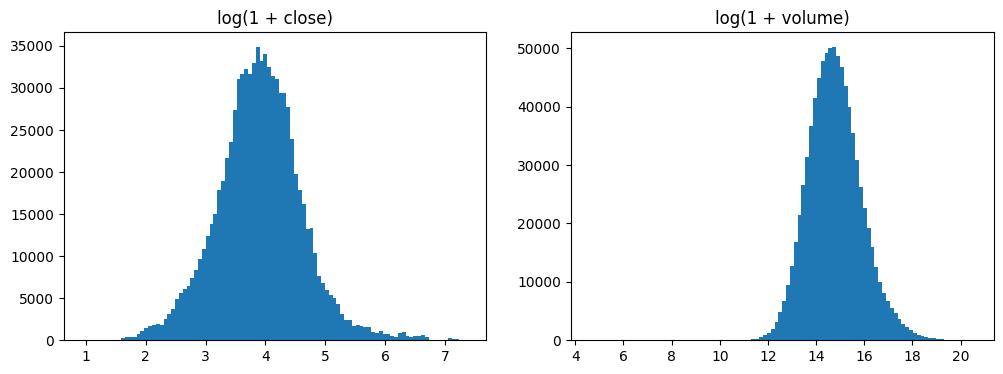

In [15]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(np.log1p(prices_clean["close"]), bins=100)
axes[0].set_title("log(1 + close)")

axes[1].hist(np.log1p(prices_clean["volume"]), bins=100)
axes[1].set_title("log(1 + volume)")

plt.show()

**Interprétation :**
- Après transformation log(1 + x), `close` et `volume` ont une distribution beaucoup plus proche d'une cloche (symétrique).
- Le log compresse les valeurs extrêmes et rend les variables plus adaptées à un réseau de neurones.
- On va l'appliquer (avant la normalisation) lors du prétraitement.

In [16]:
aapl = prices_clean[prices_clean["symbol"] == "AAPL"].sort_values("date")

aapl["close_prev"] = aapl["close"].shift(1)

print(aapl[["close", "close_prev"]].corr())

               close  close_prev
close       1.000000    0.998883
close_prev  0.998883    1.000000


**Dépendance temporelle (AAPL) :**
- La corrélation entre close(t) et close(t-1) est de 0,9989 : le prix est très persistant.
- Ce résultat est en partie dû à la tendance (série non stationnaire).
- Un modèle naïf « close(t+1) = close(t) » sera déjà très performant : il servira de référence pour juger le réseau de neurones.

**Conclusions de l'EDA :**
- Dataset : 851 264 lignes, 501 entreprises, 2010-2016, aucune valeur manquante ni doublon.
- 21 lignes à volume = 0 supprimées.
- Cible : `close`. Les prix open/high/low/close sont quasi identiques (corrélation ≈ 1).
- Échelles très différentes entre entreprises et entre variables : normalisation nécessaire.
- Distributions asymétriques : transformation log à tester.
- Série temporelle : split par date obligatoire, et comparaison à un modèle naïf.

# Tentative 1 : prédire le prix de clôture de demain

## Choix de l'étude : l'entreprise AAPL

Le dataset contient 501 entreprises. Pour la partie régression, nous travaillons uniquement sur **AAPL (Apple)**, pour deux raisons :
- **Temps de calcul** : ~1 700 lignes au lieu de ~850 000, ce qui rend le GridSearch faisable sur Kaggle.
- **Échelles homogènes** : les prix varient fortement d'une entreprise à l'autre (ex. AMZN vs JPM), ce qui compliquerait l'apprentissage d'un seul modèle.

## Définition de la tâche
- **Entrées (X)** : open, high, low, close, volume du jour *t*.
- **Cible (y)** : close du jour *t+1* (prédiction du lendemain, sans fuite d'information).
- **Découpage temporel** : entraînement 2010-2015, test 2016.
- **Référence (baseline)** : modèle naïf « close(t+1) = close(t) ».

In [17]:
import numpy as np

aapl = prices_clean[prices_clean["symbol"] == "AAPL"].sort_values("date").reset_index(drop=True)

aapl["target"] = aapl["close"].shift(-1)   # close de demain
aapl = aapl.dropna()                       # la dernière ligne n'a pas de "demain"

features = ["open", "high", "low", "close", "volume"]

train = aapl[aapl["date"] < "2016-01-01"]
test  = aapl[aapl["date"] >= "2016-01-01"]

print("Train :", len(train), "| Test :", len(test))

# Baseline naïf : prédire demain = aujourd'hui
mae_naif = np.mean(np.abs(test["target"] - test["close"]))
print("Erreur moyenne du modèle naïf (test) :", round(mae_naif, 2), "$")

Train : 1510 | Test : 251
Erreur moyenne du modèle naïf (test) : 1.05 $


In [18]:
from sklearn.preprocessing import StandardScaler

train = train.copy()
test = test.copy()

# log sur le volume (distribution très asymétrique)
train["volume"] = np.log1p(train["volume"])
test["volume"] = np.log1p(test["volume"])

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(train[features])   # fit sur le train uniquement
X_test = scaler_X.transform(test[features])         # on réutilise les mêmes paramètres

y_train = scaler_y.fit_transform(train[["target"]])
y_test = scaler_y.transform(test[["target"]])

print("Moyenne de X_train :", X_train.mean(axis=0).round(2))
print("Écart-type de X_train :", X_train.std(axis=0).round(2))
print("Moyenne de X_test :", X_test.mean(axis=0).round(2))

Moyenne de X_train : [ 0. -0.  0. -0.  0.]
Écart-type de X_train : [1. 1. 1. 1. 1.]
Moyenne de X_test : [ 1.03  1.03  1.04  1.04 -1.66]


**Normalisation :**
- Standardisation (moyenne 0, écart-type 1) apprise sur le train uniquement, puis appliquée au test (pas de fuite de données). Le volume est passé en log avant standardisation.
- Sur le test, la moyenne des prix standardisés est ≈ +1,03 et celle du volume ≈ −1,66 : 2016 diffère de la période d'entraînement (prix plus élevés, volume plus bas). C'est la conséquence de la non-stationnarité de la série.
- Risque : le modèle devra extrapoler sur des valeurs hors de la plage d'entraînement.

In [19]:
# convertir en tenseurs
import torch

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print(X_train_t.shape, y_train_t.shape)
print(X_test_t.shape, y_test_t.shape)

torch.Size([1510, 5]) torch.Size([1510, 1])
torch.Size([251, 5]) torch.Size([251, 1])


In [20]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(5, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

n_params = sum(p.numel() for p in model.parameters())
print("Nombre de paramètres :", n_params)

MLP(
  (net): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Nombre de paramètres : 2497


In [21]:
# Entrainer le modèle
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
model = MLP()

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True)

epochs = 100
train_losses, test_losses = [], []

for epoch in range(epochs):
    model.train()
    total = 0
    for xb, yb in loader:
        pred = model(xb)              # 1. forward
        loss = criterion(pred, yb)    # 2. loss
        optimizer.zero_grad()
        loss.backward()               # 3. backward
        optimizer.step()              # 4. step
        total += loss.item() * len(xb)
    train_losses.append(total / len(X_train_t))

    model.eval()
    with torch.no_grad():
        test_losses.append(criterion(model(X_test_t), y_test_t).item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d} | train loss {train_losses[-1]:.4f} | test loss {test_losses[-1]:.4f}")

Epoch  10 | train loss 0.0026 | test loss 0.0031
Epoch  20 | train loss 0.0025 | test loss 0.0033
Epoch  30 | train loss 0.0025 | test loss 0.0032
Epoch  40 | train loss 0.0024 | test loss 0.0035
Epoch  50 | train loss 0.0024 | test loss 0.0030
Epoch  60 | train loss 0.0023 | test loss 0.0031
Epoch  70 | train loss 0.0024 | test loss 0.0043
Epoch  80 | train loss 0.0023 | test loss 0.0078
Epoch  90 | train loss 0.0023 | test loss 0.0050
Epoch 100 | train loss 0.0022 | test loss 0.0029


In [22]:
# pour comparer au baseline, on reconvertit les prédictions en dollars
model.eval()
with torch.no_grad():
    pred_scaled = model(X_test_t).numpy()

pred_usd = scaler_y.inverse_transform(pred_scaled)
mae_mlp = np.mean(np.abs(pred_usd.flatten() - test["target"].values))

print("MAE du MLP (test) :", round(mae_mlp, 2), "$")
print("MAE du modèle naïf :", round(mae_naif, 2), "$")

MAE du MLP (test) : 1.11 $
MAE du modèle naïf : 1.05 $


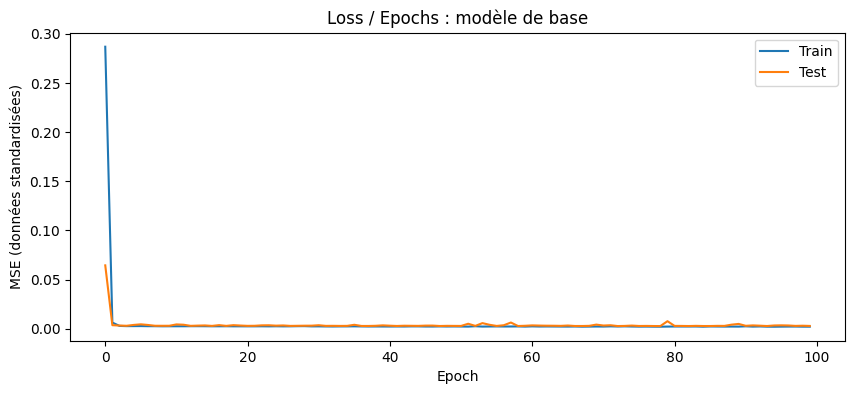

In [23]:
plt.figure(figsize=(10, 4))
plt.plot(train_losses, label="Train")
plt.plot(test_losses, label="Test")
plt.xlabel("Epoch")
plt.ylabel("MSE (données standardisées)")
plt.title("Loss / Epochs : modèle de base")
plt.legend()
plt.show()

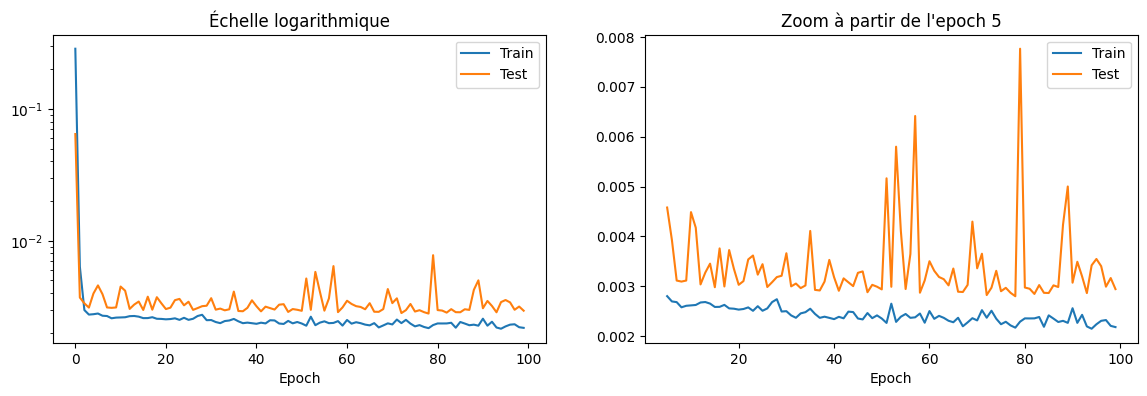

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(train_losses, label="Train")
axes[0].plot(test_losses, label="Test")
axes[0].set_yscale("log")
axes[0].set_title("Échelle logarithmique")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(range(5, 100), train_losses[5:], label="Train")
axes[1].plot(range(5, 100), test_losses[5:], label="Test")
axes[1].set_title("Zoom à partir de l'epoch 5")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.show()

**Interprétation des courbes Loss / Epochs (modèle de base) :**
- **Convergence très rapide** : la loss de train et de test chutent presque à 0 dès les 1-2 premiers epochs. La tâche est facile à apprendre, car close(t) est déjà très informatif sur close(t+1) (corrélation ≈ 0,9989).
- **Train** : après le zoom, la loss décroît lentement et régulièrement (≈ 0,0028 → 0,0022).
- **Test** : elle reste ≈ 0,001 au-dessus de celle du train, avec des pics ponctuels (ex. epoch ≈ 79), mais sans tendance à la hausse. Il n'y a donc pas de surapprentissage marqué, mais une certaine instabilité (jeu de test de 251 points, décalage entre 2010-2015 et 2016).
- **Performance** : MAE du MLP = 1,09 $, contre 1,05 $ pour le modèle naïf : le modèle de base ne bat pas la référence.
- **Remarque sur l'énoncé** : la courbe « Accuracy / Epochs » n'a pas de sens en régression (la cible est continue). Elle est remplacée par une métrique d'erreur (MAE / MSE).

In [25]:
train_gs = aapl[aapl["date"] < "2015-01-01"].copy()
val = aapl[(aapl["date"] >= "2015-01-01") & (aapl["date"] < "2016-01-01")].copy()
test = aapl[aapl["date"] >= "2016-01-01"].copy()

# log du volume sur les 3 jeux
for df in (train_gs, val, test):
    df["volume"] = np.log1p(df["volume"])

# scalers appris sur le train uniquement
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_tr = scaler_X.fit_transform(train_gs[features])
y_tr = scaler_y.fit_transform(train_gs[["target"]])

X_va = scaler_X.transform(val[features])
y_va = scaler_y.transform(val[["target"]])

X_te = scaler_X.transform(test[features])
y_te = scaler_y.transform(test[["target"]])

# tenseurs
X_tr_t, y_tr_t = torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)
X_va_t, y_va_t = torch.tensor(X_va, dtype=torch.float32), torch.tensor(y_va, dtype=torch.float32)
X_te_t, y_te_t = torch.tensor(X_te, dtype=torch.float32), torch.tensor(y_te, dtype=torch.float32)

print("Train :", X_tr_t.shape, "| Val :", X_va_t.shape, "| Test :", X_te_t.shape)
print("Moyenne de X_val :", X_va.mean(axis=0).round(2))

# baseline naïf sur la validation
mae_naif_val = np.mean(np.abs(val["target"] - val["close"]))
print("MAE du modèle naïf (validation) :", round(mae_naif_val, 2), "$")

Train : torch.Size([1258, 5]) | Val : torch.Size([252, 5]) | Test : torch.Size([251, 5])
Moyenne de X_val : [ 2.49  2.49  2.48  2.49 -1.47]
MAE du modèle naïf (validation) : 1.49 $


**Découpage temporel (tentative 1 : prédire le prix) :**
- Train : 2010-2014 (1258 jours) | Validation : 2015 (252) | Test : 2016 (251).
- Le jeu de validation sert à comparer les hyperparamètres. Dans la tentative 2, le test n'est utilisé qu'une seule fois, à la fin ; le test 2016 a déjà servi à évaluer le premier modèle de la tentative 1, qui n'a pas été retenu.
- Les scalers sont appris sur le train uniquement.
- Sur la validation, la moyenne des prix standardisés est ≈ +2,49 : les prix de 2015 sont bien au-dessus de ceux de la période d'entraînement. La série étant non stationnaire, prédire le niveau du prix oblige le modèle à extrapoler.
- Baseline naïf sur la validation : MAE = 1,49 $.

# Tentative 2 : prédire le rendement du lendemain

**Constat (tentative 1) :** en prédisant le prix, les entrées standardisées de la validation (2015) sont en moyenne à +2,49 écarts-types de celles de l'entraînement : la série est non stationnaire et le modèle doit extrapoler. De plus, close(t) est presque égal à close(t+1), ce qui rend le score trompeur.

**Nouvelle tâche :**
- Cible : rendement de demain = close(t+1) / close(t) − 1
- Entrées : ret_1 (rendement du jour), oc_chg (close/open), hl_range ((high − low)/close), vol_chg (variation du log du volume)
- Baseline naïf : « rendement = 0 », soit close(t+1) = close(t) (MAE : 1,49 $ en validation, 1,05 $ en test)
- Les statistiques par année montrent que ces variables restent dans la même plage de 2010 à 2016.

In [26]:
aapl2 = prices_clean[prices_clean["symbol"] == "AAPL"].sort_values("date").reset_index(drop=True)

aapl2["ret_1"] = aapl2["close"].pct_change()
aapl2["oc_chg"] = (aapl2["close"] - aapl2["open"]) / aapl2["open"]
aapl2["hl_range"] = (aapl2["high"] - aapl2["low"]) / aapl2["close"]
aapl2["vol_chg"] = np.log1p(aapl2["volume"]).diff()
aapl2["target_ret"] = aapl2["close"].shift(-1) / aapl2["close"] - 1

aapl2 = aapl2.dropna().reset_index(drop=True)
features2 = ["ret_1", "oc_chg", "hl_range", "vol_chg"]

print(aapl2.groupby(aapl2["date"].dt.year)[features2 + ["target_ret"]].mean().round(4))
print(aapl2.groupby(aapl2["date"].dt.year)[features2 + ["target_ret"]].std().round(4))

       ret_1  oc_chg  hl_range  vol_chg  target_ret
date                                               
2010  0.0018 -0.0004    0.0218  -0.0037      0.0019
2011  0.0010 -0.0001    0.0195  -0.0003      0.0010
2012  0.0013 -0.0008    0.0207   0.0052      0.0013
2013  0.0004 -0.0009    0.0202  -0.0043      0.0002
2014  0.0014  0.0006    0.0165  -0.0012      0.0014
2015 -0.0000 -0.0010    0.0202  -0.0001     -0.0000
2016  0.0005  0.0010    0.0168  -0.0040      0.0005
       ret_1  oc_chg  hl_range  vol_chg  target_ret
date                                               
2010  0.0169  0.0140    0.0181   0.3059      0.0169
2011  0.0165  0.0135    0.0099   0.3305      0.0165
2012  0.0186  0.0153    0.0110   0.3257      0.0187
2013  0.0180  0.0130    0.0089   0.3210      0.0179
2014  0.0137  0.0109    0.0085   0.3391      0.0136
2015  0.0168  0.0151    0.0132   0.3266      0.0168
2016  0.0147  0.0108    0.0085   0.3223      0.0148


In [27]:
train2 = aapl2[aapl2["date"] < "2015-01-01"]
val2 = aapl2[(aapl2["date"] >= "2015-01-01") & (aapl2["date"] < "2016-01-01")]
test2 = aapl2[aapl2["date"] >= "2016-01-01"]

scaler_X2 = StandardScaler()
scaler_y2 = StandardScaler()

X_tr = scaler_X2.fit_transform(train2[features2])
y_tr = scaler_y2.fit_transform(train2[["target_ret"]])
X_va = scaler_X2.transform(val2[features2])
y_va = scaler_y2.transform(val2[["target_ret"]])
X_te = scaler_X2.transform(test2[features2])
y_te = scaler_y2.transform(test2[["target_ret"]])

X_tr_t, y_tr_t = torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)
X_va_t, y_va_t = torch.tensor(X_va, dtype=torch.float32), torch.tensor(y_va, dtype=torch.float32)
X_te_t, y_te_t = torch.tensor(X_te, dtype=torch.float32), torch.tensor(y_te, dtype=torch.float32)

print("Train :", X_tr_t.shape, "| Val :", X_va_t.shape, "| Test :", X_te_t.shape)
print("Moyenne de X_val :", X_va.mean(axis=0).round(2))
print("Moyenne de X_test :", X_te.mean(axis=0).round(2))

# Baseline naïf en dollars : close(t+1) = close(t)
mae_naif_val = np.mean(np.abs(val2["close"] * val2["target_ret"]))
mae_naif_test = np.mean(np.abs(test2["close"] * test2["target_ret"]))
print("MAE naïf validation :", round(mae_naif_val, 2), "$ | test :", round(mae_naif_test, 2), "$")

Train : torch.Size([1257, 4]) | Val : torch.Size([252, 4]) | Test : torch.Size([251, 4])
Moyenne de X_val : [-0.07 -0.05  0.04  0.  ]
Moyenne de X_test : [-0.04  0.1  -0.25 -0.01]
MAE naïf validation : 1.49 $ | test : 1.05 $


In [28]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print("Nombre de paramètres :", sum(p.numel() for p in model.parameters()))

Nombre de paramètres : 2433


In [29]:
torch.manual_seed(42)
model = MLP()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)

epochs = 100
train_losses, val_losses = [], []

for epoch in range(epochs):
    model.train()
    total = 0
    for xb, yb in loader:
        loss = criterion(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    train_losses.append(total / len(X_tr_t))

    model.eval()
    with torch.no_grad():
        val_losses.append(criterion(model(X_va_t), y_va_t).item())

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1:3d} | train {train_losses[-1]:.4f} | val {val_losses[-1]:.4f}")

Epoch  20 | train 0.9467 | val 1.0007
Epoch  40 | train 0.9125 | val 1.0145
Epoch  60 | train 0.8836 | val 1.0399
Epoch  80 | train 0.8565 | val 1.0337
Epoch 100 | train 0.8345 | val 1.0711


In [30]:
zero_scaled = (0 - scaler_y2.mean_[0]) / scaler_y2.scale_[0]    # "rendement = 0" en valeur standardisée
naive_val_loss = np.mean((zero_scaled - y_va) ** 2)
print("Loss validation du modèle naïf :", round(naive_val_loss, 4))
print("Meilleure loss validation du MLP :", round(min(val_losses), 4), "à l'epoch", int(np.argmin(val_losses)) + 1)

Loss validation du modèle naïf : 1.0008
Meilleure loss validation du MLP : 0.9829 à l'epoch 10


**Modèle de base sur la nouvelle tâche (rendement de demain) :**
- La loss de train baisse (0,95 → 0,83) mais celle de validation remonte (1,00 → 1,07) : surapprentissage.
- Le modèle naïf (rendement = 0) obtient une loss de validation de 1,0008 ; le meilleur MLP (epoch 10) obtient 0,9829, soit un gain d'environ 1,8 % seulement.
- Le rendement quotidien est dominé par le bruit : le MLP n'extrait presque aucun signal utile.
- Cette situation justifie le GridSearch et la régularisation (réseau plus petit, dropout, L2, early stopping).

**Choix de l'outil :** `GridSearchCV` s'applique à des estimateurs sklearn, et sa validation croisée classique entraînerait parfois sur le futur pour prédire le passé. Nous utilisons `ParameterGrid` (sklearn) pour générer les combinaisons, et nous évaluons chacune sur une validation placée après le train (2015).

In [31]:
def train_model(hidden=(64, 32), lr=0.001, epochs=20, opt_name="adam"):
    torch.manual_seed(42)

    # construit le réseau : 4 entrées -> couches cachées -> 1 sortie
    layers, prev = [], 4
    for h in hidden:
        layers += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    layers.append(nn.Linear(prev, 1))
    model = nn.Sequential(*layers)

    criterion = nn.MSELoss()
    if opt_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)

    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_va_t), y_va_t).item()
    return val_loss

In [32]:
print(train_model())
print(train_model(hidden=(16,), epochs=10))

1.0007197856903076
1.0252305269241333


In [33]:
from sklearn.model_selection import ParameterGrid

grid = {
    "hidden": [(64, 32), (16,)],
    "lr": [0.001, 0.0001],
    "epochs": [10, 30],
    "opt_name": ["adam", "sgd"],
}

results = []
for params in ParameterGrid(grid):
    results.append({**params, "val_loss": train_model(**params)})

res = pd.DataFrame(results).sort_values("val_loss")
print(res.to_string(index=False))

 epochs   hidden     lr opt_name  val_loss
     10 (64, 32) 0.0010     adam  0.982890
     30 (64, 32) 0.0001     adam  0.985907
     10 (64, 32) 0.0001     adam  0.987875
     10 (64, 32) 0.0010      sgd  0.992028
     30 (64, 32) 0.0010      sgd  0.993775
     30 (64, 32) 0.0001      sgd  0.998394
     10 (64, 32) 0.0001      sgd  1.009803
     30 (64, 32) 0.0010     adam  1.017971
     30    (16,) 0.0010     adam  1.020721
     10    (16,) 0.0010     adam  1.025231
     30    (16,) 0.0010      sgd  1.031367
     30    (16,) 0.0001     adam  1.047540
     10    (16,) 0.0010      sgd  1.053118
     10    (16,) 0.0001     adam  1.066004
     30    (16,) 0.0001      sgd  1.071365
     10    (16,) 0.0001      sgd  1.081001


**Résultats du GridSearch (16 combinaisons, évaluées sur la validation 2015) :**
- Grille : architecture {(64,32), (16,)}, learning rate {1e-3, 1e-4}, epochs {10, 30}, optimiseur {Adam, SGD}.
- Meilleure configuration : (64,32), lr = 0,001, Adam, 10 epochs → loss de validation = 0,9829 (modèle naïf : 1,0008).
- Tendances : pour le réseau (64,32), Adam avec lr = 1e-3 atteint son minimum tôt (10 epochs) puis surapprend (1,018 à 30 epochs) ; avec un pas plus faible (lr = 1e-4), 30 epochs donnent un meilleur résultat que 10, pour toutes les configurations. Le nombre d'epochs optimal dépend donc du learning rate.
- Adam est meilleur que SGD à 10 epochs ; à 30 epochs, il ne perd contre SGD que pour (64,32) avec lr = 1e-3.
- Les réseaux (16,) restent moins bons que le naïf (> 1,02).
- Limites : le gain sur le naïf est faible (≈ 1,8 %) et les écarts entre les meilleures configurations sont de l'ordre du bruit (un seul entraînement par configuration, une seule graine).

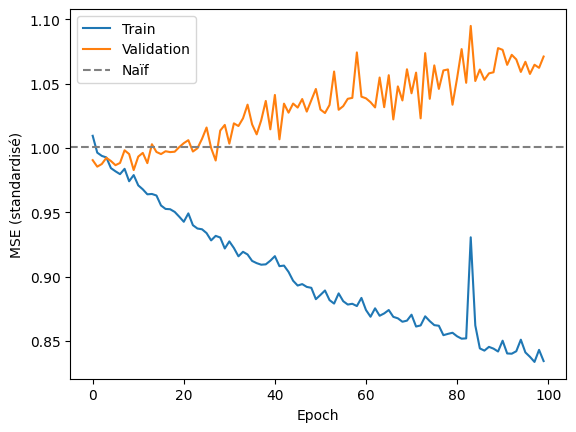

In [34]:
plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.axhline(1.0008, color="gray", linestyle="--", label="Naïf")
plt.xlabel("Epoch")
plt.ylabel("MSE (standardisé)")
plt.legend()
plt.show()

**Courbes Loss / Epochs (réseau 64-32, Adam, lr = 0,001, 100 epochs) :**
- La loss de train décroît régulièrement (≈ 1,0 → 0,83) tandis que la loss de validation passe sous le modèle naïf pendant les ~10 premiers epochs, puis remonte (≈ 1,07) : surapprentissage.
- L'écart train/validation augmente avec les epochs : le réseau mémorise du bruit de la période d'entraînement.
- Le GridSearch retient 10 epochs, ce qui correspond au minimum de la loss de validation.
- Un pic ponctuel de la loss de train (epoch ≈ 83) traduit une instabilité de l'optimisation, sans effet durable.
- L'« accuracy » n'a pas de sens en régression : la loss (MSE) et le MAE en dollars la remplacent.

In [35]:
# Régularisation 1 : Early stopping (patience = 10) :
import copy

torch.manual_seed(42)
model_es = MLP()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_es.parameters(), lr=0.001)
loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)

max_epochs = 100
patience = 10                    
best_val = float("inf")           
best_state = None                  
wait = 0                           
train_losses_es, val_losses_es = [], []

for epoch in range(max_epochs):
    model_es.train()
    total = 0
    for xb, yb in loader:
        loss = criterion(model_es(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    train_losses_es.append(total / len(X_tr_t))

    model_es.eval()
    with torch.no_grad():
        val = criterion(model_es(X_va_t), y_va_t).item()
    val_losses_es.append(val)

    if val < best_val:                                  
        best_val = val
        best_state = copy.deepcopy(model_es.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Arrêt à l'epoch", epoch + 1)
            break

model_es.load_state_dict(best_state)                    
print("Meilleure loss validation :", round(best_val, 4))
print("Epoch du meilleur modèle :", int(np.argmin(val_losses_es)) + 1)

Arrêt à l'epoch 20
Meilleure loss validation : 0.9829
Epoch du meilleur modèle : 10


**Régularisation 1 : Early stopping (patience = 10) :**
- Le meilleur modèle est trouvé à l'epoch 10 (loss de validation = 0,9829) ; l'entraînement s'arrête à l'epoch 20 et les poids de l'epoch 10 sont restaurés.
- Comparé au modèle de base entraîné 100 epochs (loss de validation ≈ 1,07, surapprentissage), la loss de validation baisse nettement.
- Le gain sur le modèle naïf (1,0008) reste faible (≈ 1,8 %) : le signal du rendement journalier est très bruité.
- Le choix de l'epoch se fait sur la validation, donc ce score est légèrement optimiste ; le test sera évalué une seule fois à la fin.

In [36]:
# Régularisation 2 : Dropout
import copy

class MLP_Dropout(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 64),
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
model_do = MLP_Dropout(p=0.3)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_do.parameters(), lr=0.001)
loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)

max_epochs = 100
patience = 10
best_val = float("inf")
best_state = None
wait = 0
train_losses_do, val_losses_do = [], []

for epoch in range(max_epochs):
    model_do.train()          # dropout ACTIF
    total = 0
    for xb, yb in loader:
        loss = criterion(model_do(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    train_losses_do.append(total / len(X_tr_t))

    model_do.eval()           # dropout COUPÉ
    with torch.no_grad():
        val = criterion(model_do(X_va_t), y_va_t).item()
    val_losses_do.append(val)

    if val < best_val:
        best_val = val
        best_state = copy.deepcopy(model_do.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Arrêt à l'epoch", epoch + 1)
            break

model_do.load_state_dict(best_state)
print("Meilleure loss validation :", round(best_val, 4))
print("Epoch du meilleur modèle :", int(np.argmin(val_losses_do)) + 1)

Arrêt à l'epoch 22
Meilleure loss validation : 0.9839
Epoch du meilleur modèle : 12


**Régularisation 2 : Dropout (p = 0,3) + early stopping :**
- Meilleure loss de validation = 0,9839 (epoch 12), contre 0,9829 pour l'early stopping seul : pas d'amélioration (écart dans le bruit).
- Explication probable : le problème vient du faible rapport signal/bruit du rendement journalier, pas d'un excès de capacité du réseau que le dropout pourrait corriger.

In [37]:
# Régularisation 3 : L2 (weight decay)
torch.manual_seed(42)
model_l2 = MLP()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_l2.parameters(), lr=0.001, weight_decay=1e-2)
loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)

max_epochs = 100
patience = 10
best_val = float("inf")
best_state = None
wait = 0
train_losses_l2, val_losses_l2 = [], []

for epoch in range(max_epochs):
    model_l2.train()
    total = 0
    for xb, yb in loader:
        loss = criterion(model_l2(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    train_losses_l2.append(total / len(X_tr_t))

    model_l2.eval()
    with torch.no_grad():
        val = criterion(model_l2(X_va_t), y_va_t).item()
    val_losses_l2.append(val)

    if val < best_val:
        best_val = val
        best_state = copy.deepcopy(model_l2.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Arrêt à l'epoch", epoch + 1)
            break

model_l2.load_state_dict(best_state)
print("Meilleure loss validation :", round(best_val, 4))
print("Epoch du meilleur modèle :", int(np.argmin(val_losses_l2)) + 1)

Arrêt à l'epoch 20
Meilleure loss validation : 0.984
Epoch du meilleur modèle : 10


**Régularisation 3 : L2 (weight decay = 1e-2) + early stopping :**
- Meilleure loss de validation = 0,984 (epoch 10), identique à l'early stopping seul.

**Comparaison des techniques de régularisation :**
- Sans régularisation, le modèle de base (100 epochs) surapprend : la loss de validation remonte à ≈ 1,07, au-dessus du modèle naïf (1,0008).
- Les trois variantes régularisées donnent ≈ 0,983-0,984, soit environ 1,7 % sous le naïf. Les écarts entre elles sont dans le bruit (une seule graine).
- L'early stopping est la technique qui compte ici ; le dropout et le L2 n'apportent rien de mesurable.
- Explication probable : le rendement journalier est dominé par le bruit, il y a très peu de signal à extraire.

In [38]:
model_es.eval()
with torch.no_grad():
    pred_scaled = model_es(X_te_t).numpy()

# loss (espace standardisé)
loss_test = np.mean((pred_scaled - y_te) ** 2)
zero_scaled = (0 - scaler_y2.mean_[0]) / scaler_y2.scale_[0]
loss_naif_test = np.mean((zero_scaled - y_te) ** 2)

# erreur en dollars : retour au rendement, puis x close
pred_ret = pred_scaled.flatten() * scaler_y2.scale_[0] + scaler_y2.mean_[0]
mae_mlp_test = np.mean(np.abs(test2["close"].values * (pred_ret - test2["target_ret"].values)))

print("Loss test  | MLP :", round(loss_test, 4), "| naïf :", round(loss_naif_test, 4))
print("MAE test   | MLP :", round(mae_mlp_test, 3), "$ | naïf :", round(mae_naif_test, 3), "$")

Loss test  | MLP : 0.7531 | naïf : 0.7696
MAE test   | MLP : 1.041 $ | naïf : 1.047 $


**Évaluation finale sur le test (2016), modèle retenu : MLP 64-32 + early stopping :**
- MAE = 1,041 $ contre 1,047 $ pour le modèle naïf ; loss = 0,7531 contre 0,7696.
- Le MLP est légèrement meilleur, mais l'écart (≈ 0,6 % en MAE) est trop faible pour conclure à une réelle supériorité (251 jours de test, une seule graine).
- Conclusion : le rendement quotidien d'AAPL est dominé par le bruit ; ces variables ne permettent d'améliorer que marginalement la prédiction « variation nulle ».

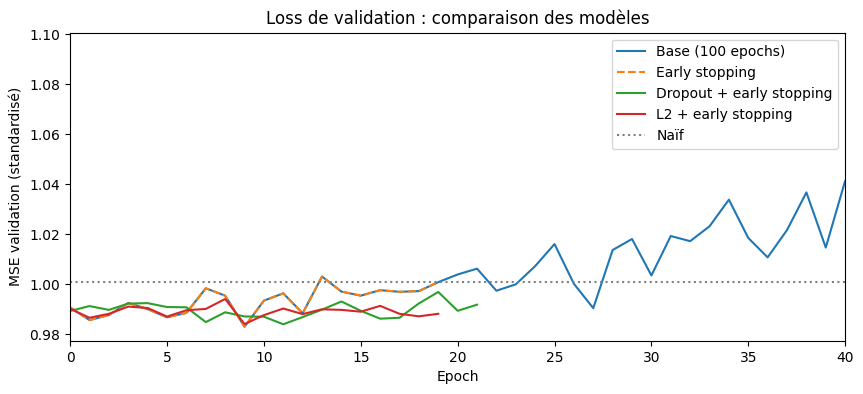

In [39]:
plt.figure(figsize=(10, 4))
plt.plot(val_losses, label="Base (100 epochs)")
plt.plot(val_losses_es, label="Early stopping", linestyle="--")
plt.plot(val_losses_do, label="Dropout + early stopping")
plt.plot(val_losses_l2, label="L2 + early stopping")
plt.axhline(1.0008, color="gray", linestyle=":", label="Naïf")
plt.xlim(0, 40)
plt.xlabel("Epoch")
plt.ylabel("MSE validation (standardisé)")
plt.title("Loss de validation : comparaison des modèles")
plt.legend()
plt.show()

**Comparaison des modèles (loss de validation) :**
- Pendant les ~20 premiers epochs, les quatre courbes oscillent entre ≈ 0,983 et 1,00, autour du modèle naïf (1,0008). Base et early stopping sont identiques (même graine, même entraînement ; l'early stopping coupe simplement l'entraînement).
- Sans arrêt, la loss de validation de la base dépasse le naïf après l'epoch ~21 et atteint ≈ 1,07 à 100 epochs : surapprentissage.
- Dropout et L2 ne modifient pas visiblement la courbe.
- Les fluctuations d'un epoch à l'autre (±0,01) sont du même ordre que l'avance sur le naïf : l'avantage du MLP est faible et le choix du meilleur epoch est sensible au bruit.

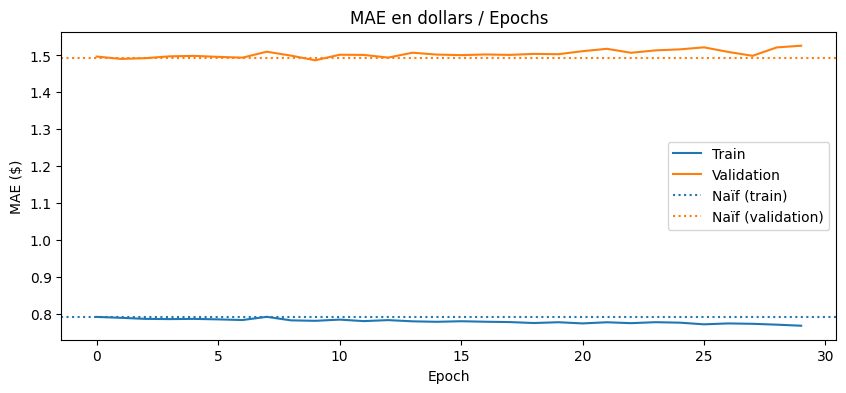

In [40]:
def mae_usd(pred_scaled, df):
    pred_ret = pred_scaled.flatten() * scaler_y2.scale_[0] + scaler_y2.mean_[0]
    return np.mean(np.abs(df["close"].values * (pred_ret - df["target_ret"].values)))

mae_naif_tr = np.mean(np.abs(train2["close"] * train2["target_ret"]))

torch.manual_seed(42)
model_m = MLP()
optimizer = torch.optim.Adam(model_m.parameters(), lr=0.001)
criterion = nn.MSELoss()
loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=32, shuffle=True)

mae_tr_hist, mae_va_hist = [], []
for epoch in range(30):
    model_m.train()
    for xb, yb in loader:
        loss = criterion(model_m(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    model_m.eval()
    with torch.no_grad():
        mae_tr_hist.append(mae_usd(model_m(X_tr_t).numpy(), train2))
        mae_va_hist.append(mae_usd(model_m(X_va_t).numpy(), val2))

plt.figure(figsize=(10, 4))
plt.plot(mae_tr_hist, label="Train")
plt.plot(mae_va_hist, label="Validation")
plt.axhline(mae_naif_tr, color="C0", linestyle=":", label="Naïf (train)")
plt.axhline(mae_naif_val, color="C1", linestyle=":", label="Naïf (validation)")
plt.xlabel("Epoch")
plt.ylabel("MAE ($)")
plt.title("MAE en dollars / Epochs")
plt.legend()
plt.show()

**Remplacement de « Accuracy / Epochs » :**
En régression, la cible est continue : l'accuracy (proportion de prédictions exactes) n'a pas de sens. Nous suivons à la place le MAE en dollars à chaque epoch.

**Interprétation :**
- Train : MAE ≈ 0,79 $, presque identique au modèle naïf (≈ 0,79 $), avec une très légère baisse au fil des epochs.
- Validation : MAE ≈ 1,49-1,53 $, sur la ligne du naïf puis légèrement au-dessus : le réseau ne fait pas mieux que « variation nulle » en dollars.
- Cohérent avec le test (1,041 $ contre 1,047 $ pour le naïf) : le réseau ne fait pas nettement mieux que le naïf.
- Les écarts de loss (MSE sur rendements) et de MAE en dollars ne mesurent pas la même chose, d'où un gain visible sur l'une et pas sur l'autre.

| Modèle (validation 2015) | Loss |
|---|---|
| Naïf (rendement = 0) | 1,0008 |
| MLP de base, 100 epochs (dernier epoch) | ≈ 1,07 |
| + Early stopping | 0,9829 |
| + Dropout + early stopping | 0,9839 |
| + L2 + early stopping | 0,984 |

Test 2016 (modèle retenu : early stopping seul) : MAE = 1,041 $ contre 1,047 $ pour le naïf.

### Part 2: classification multi-classes (maintenance prédictive)

In [41]:
import pandas as pd
path = "/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification"
df = pd.read_csv(path +"/predictive_maintenance.csv")
print(df.shape)
df.head()

(10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


In [43]:
print(df["Failure Type"].value_counts())
print()
print(df["Failure Type"].value_counts(normalize=True).round(4) * 100)

Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64

Failure Type
No Failure                  96.52
Heat Dissipation Failure     1.12
Power Failure                0.95
Overstrain Failure           0.78
Tool Wear Failure            0.45
Random Failures              0.18
Name: proportion, dtype: float64


In [44]:
pd.crosstab(df["Failure Type"], df["Target"])

Target,0,1
Failure Type,,
Heat Dissipation Failure,0,112
No Failure,9643,9
Overstrain Failure,0,78
Power Failure,0,95
Random Failures,18,0
Tool Wear Failure,0,45


In [45]:
bad = ((df["Failure Type"] == "No Failure") & (df["Target"] == 1)) | \
      ((df["Failure Type"] == "Random Failures") & (df["Target"] == 0))

print("Lignes incohérentes :", bad.sum())

df_clean = df[~bad].copy()
print(df.shape, "->", df_clean.shape)
print(df_clean["Failure Type"].value_counts())

Lignes incohérentes : 27
(10000, 10) -> (9973, 10)
Failure Type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Name: count, dtype: int64


**Nettoyage :**
- Aucune valeur manquante. `UDI` et `Product ID` sont des identifiants sans valeur prédictive (à retirer) ; `Target` est dérivée de la cible (fuite d'information) et ne sera pas utilisée comme entrée.
- 27 lignes ont des étiquettes contradictoires entre `Target` et `Failure Type` (9 « No Failure » avec Target = 1, 18 « Random Failures » avec Target = 0) : elles sont supprimées.
- La classe « Random Failures » disparaît : il reste 5 classes.
- Le dataset reste très déséquilibré (≈ 96,7 % de « No Failure »).

['Type', 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'failure_type']


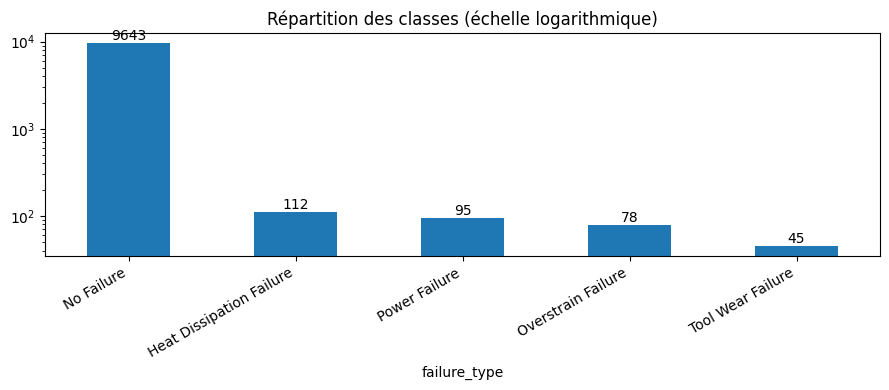

In [46]:
# renommer, retirer les colonnes inutiles, voir le déséquilibre
import matplotlib.pyplot as plt

df_clean = df_clean.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Failure Type": "failure_type",
})
df_clean = df_clean.drop(columns=["UDI", "Product ID", "Target"])
print(df_clean.columns.tolist())

counts = df_clean["failure_type"].value_counts()
plt.figure(figsize=(9, 4))
ax = counts.plot(kind="bar")
ax.set_yscale("log")
for i, v in enumerate(counts):
    ax.text(i, v, str(v), ha="center", va="bottom")
plt.title("Répartition des classes (échelle logarithmique)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Répartition des classes :**
- « No Failure » représente ≈ 96,7 % des lignes (9643) ; les pannes sont rares : Heat Dissipation 112, Power 95, Overstrain 78, Tool Wear 45.
- L'échelle logarithmique atténue visuellement l'écart : le rapport entre « No Failure » et « Tool Wear Failure » est d'environ 214.
- Un modèle répondant toujours « No Failure » aurait ≈ 96,7 % d'accuracy sans détecter aucune panne : l'accuracy seule est trompeuse, d'où l'usage du rappel (sensibilité), de la précision et du F1 par classe, et la nécessité d'équilibrer le jeu d'entraînement.

In [47]:
num_cols = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]

print(df_clean[num_cols].describe().round(1))
print()
print(df_clean.groupby("failure_type")[num_cols].mean().round(1))

       air_temp  process_temp     rpm  torque  tool_wear
count    9973.0        9973.0  9973.0  9973.0     9973.0
mean      300.0         310.0  1538.9    40.0      107.9
std         2.0           1.5   179.4    10.0       63.6
min       295.3         305.7  1168.0     3.8        0.0
25%       298.3         308.8  1423.0    33.2       53.0
50%       300.1         310.1  1503.0    40.1      108.0
75%       301.5         311.1  1612.0    46.7      162.0
max       304.5         313.8  2886.0    76.6      253.0

                          air_temp  process_temp     rpm  torque  tool_wear
failure_type                                                               
Heat Dissipation Failure     302.6         310.8  1338.0    52.8      107.3
No Failure                   300.0         310.0  1540.4    39.6      106.7
Overstrain Failure           299.9         310.1  1354.2    56.9      208.2
Power Failure                300.1         310.0  1764.0    48.5      101.9
Tool Wear Failure            3

**Mesures par type de panne :**
- Les mesures ont des échelles très différentes (rpm ≈ 1500, température ≈ 300, couple ≈ 40) : standardisation nécessaire.
- Tool Wear Failure : tool_wear ≈ 217 min contre ≈ 107 pour « No Failure », cohérent avec son nom. Overstrain a aussi un tool_wear élevé (≈ 208) mais un couple plus fort (≈ 57) : les deux classes ne se distinguent que par le couple.
- Heat Dissipation : température de l'air plus élevée et rpm plus faible ; l'écart process_temp − air_temp est plus petit (8,2 contre 10,0).
- Power Failure : rpm et couple plus élevés.
- Seules les moyennes sont comparées ici : les distributions peuvent se chevaucher, ce que les boxplots permettent de vérifier.

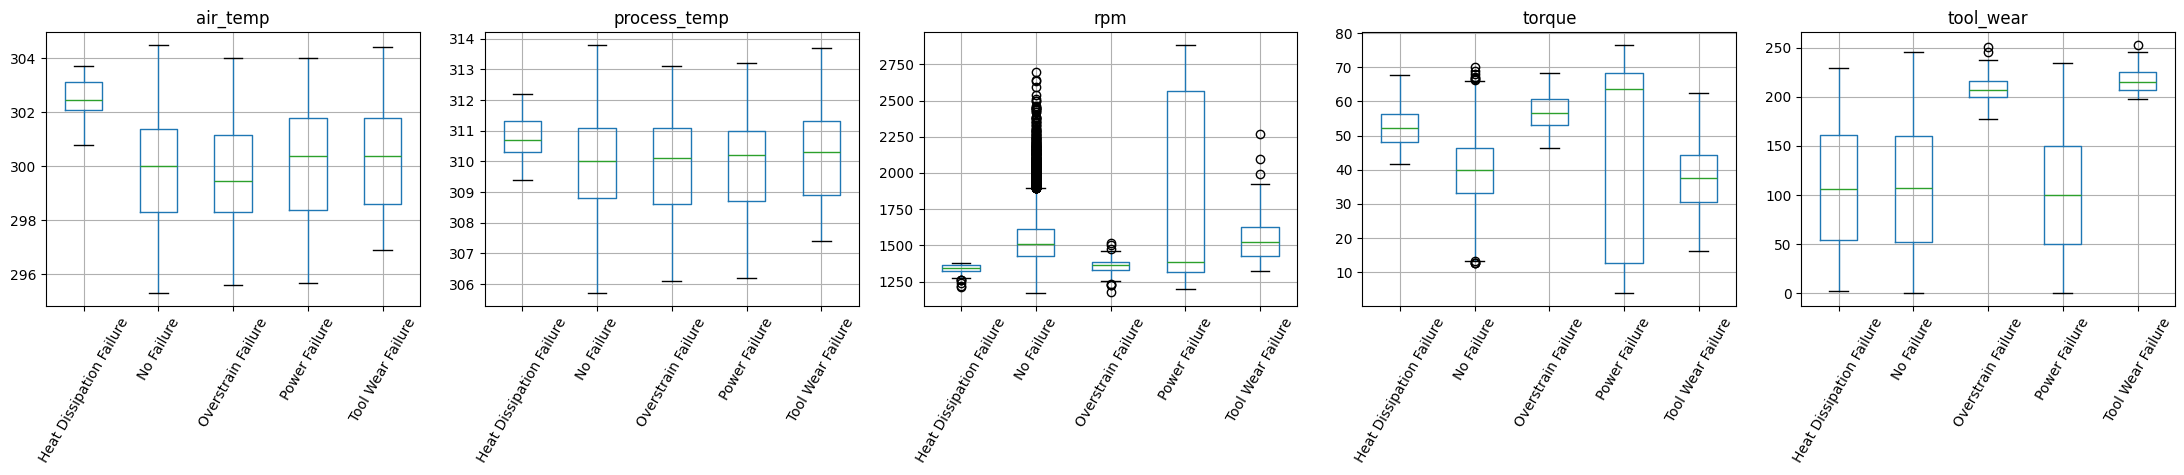

In [48]:
# boxplot
fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, col in zip(axes, num_cols):
    df_clean.boxplot(column=col, by="failure_type", ax=ax, rot=60)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Boxplots par classe :**
- `process_temp` ne distingue quasiment aucune classe ; `air_temp` ne sépare que Heat Dissipation (plus élevée).
- `tool_wear` sépare Overstrain et Tool Wear Failure (≈ 200-225 min) des autres, mais ces deux classes ne se distinguent entre elles que par le couple (élevé pour Overstrain, faible pour Tool Wear).
- Power Failure présente de très larges boîtes en rpm et en couple, ce qui suggère plusieurs sous-groupes : les moyennes seules étaient trompeuses.
- Les valeurs extrêmes de rpm en « No Failure » sont des valeurs de fonctionnement réelles : elles sont conservées.
- Aucune mesure ne suffit à elle seule : le modèle doit combiner plusieurs variables, et des confusions entre classes sont à prévoir.

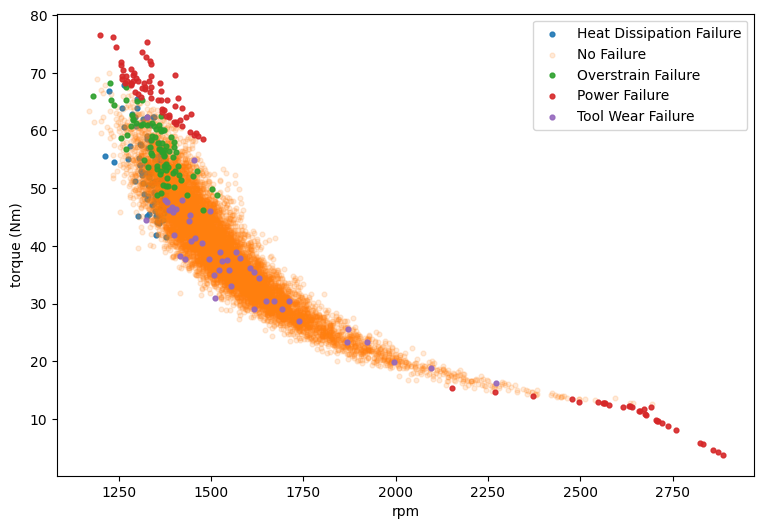

In [49]:
plt.figure(figsize=(9, 6))
for cls, sub in df_clean.groupby("failure_type"):
    alpha = 0.15 if cls == "No Failure" else 0.9
    plt.scatter(sub["rpm"], sub["torque"], s=12, alpha=alpha, label=cls)
plt.xlabel("rpm")
plt.ylabel("torque (Nm)")
plt.legend()
plt.show()

**Couple en fonction du rpm :**
- Les points « No Failure » forment une courbe décroissante (couple élevé à rpm bas, couple faible à rpm élevé).
- Power Failure se trouve aux deux extrémités de cette courbe (couple très haut à rpm bas, ou rpm très haut avec couple très bas) : la panne est liée au produit couple × vitesse, pas à une mesure isolée.
- Overstrain et Heat Dissipation se concentrent à rpm bas ; Tool Wear est mélangé au nuage « No Failure » : seule `tool_wear` le distingue, partiellement.
- Idée : créer des variables combinées (puissance, écart de température, usure × couple).

In [50]:
# tester des variables construites
import numpy as np

df_clean["power"] = df_clean["torque"] * df_clean["rpm"] * 2 * np.pi / 60
df_clean["temp_diff"] = df_clean["process_temp"] - df_clean["air_temp"]
df_clean["wear_torque"] = df_clean["tool_wear"] * df_clean["torque"]

new_cols = ["power", "temp_diff", "wear_torque"]
print(df_clean.groupby("failure_type")[new_cols].agg(["min", "mean", "max"]).round(1))

                           power                  temp_diff              \
                             min    mean      max       min  mean   max   
failure_type                                                              
Heat Dissipation Failure  5913.7  7383.5   8967.3       7.6   8.2   8.6   
No Failure                3515.0  6243.7   8998.0       7.6  10.0  12.1   
Overstrain Failure        6923.3  8043.1   8977.1       8.4  10.2  12.0   
Power Failure             1148.4  7251.8  10469.9       7.6   9.9  11.9   
Tool Wear Failure         3852.7  5945.8   8658.2       7.8   9.9  11.5   

                         wear_torque                    
                                 min     mean      max  
failure_type                                            
Heat Dissipation Failure       116.4   5670.6  14999.5  
No Failure                       0.0   4212.2  11919.8  
Overstrain Failure           11003.2  11794.2  14040.0  
Power Failure                    0.0   5018.7  16497.0  


**Variables construites (puissance, écart de température, usure × couple) :**
- `power` (couple × vitesse angulaire) : Power Failure dépasse les bornes de « No Failure » des deux côtés (min 1148, max 10470, contre 3515 à 8998).
- `temp_diff` : Heat Dissipation reste toujours sous 8,6 (moyenne 8,2 contre 10,0 pour « No Failure »).
- `wear_torque` : Overstrain est toujours ≥ 11003, alors que « No Failure » dépasse très rarement cette valeur.
- Les bornes de « No Failure » ressemblent à des seuils : les étiquettes semblent générées par des règles sur les mesures. Les performances élevées éventuelles ne refléteront donc pas la difficulté d'un cas réel.
- Ces variables sont conservées comme entrées du modèle (elles ne dépendent pas de l'étiquette).

In [51]:
# voir si Type est utile comme feature
print(df_clean["Type"].value_counts())
print()
print((pd.crosstab(df_clean["Type"], df_clean["failure_type"], normalize="index") * 100).round(2))

Type
L    5984
M    2991
H     998
Name: count, dtype: int64

failure_type  Heat Dissipation Failure  No Failure  Overstrain Failure  \
Type                                                                     
H                                 0.80       98.00                0.10   
L                                 1.24       96.14                1.22   
M                                 1.00       97.36                0.13   

failure_type  Power Failure  Tool Wear Failure  
Type                                            
H                      0.50               0.60  
L                      0.99               0.42  
M                      1.04               0.47  


**Variable `Type` :**
- Répartition : L 60 %, M 30 %, H 10 %.
- Les pannes ne se répartissent pas pareil selon le Type : Overstrain est ≈ 10 fois plus fréquent pour L (1,22 %) que pour M (0,13 %) ou H (0,10 %). Les effectifs sont toutefois très faibles (≈ 1 ligne pour H), donc l'effet est à interpréter avec prudence.
- `Type` est conservée et encodée en one-hot (pas d'ordre imposé).

In [52]:
from sklearn.model_selection import train_test_split

classes = ["No Failure", "Heat Dissipation Failure", "Power Failure",
           "Overstrain Failure", "Tool Wear Failure"]
class_to_id = {c: i for i, c in enumerate(classes)}

y = df_clean["failure_type"].map(class_to_id)
X = pd.get_dummies(df_clean.drop(columns="failure_type"), columns=["Type"], dtype=float)
print(X.columns.tolist())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train :", y_train.value_counts().sort_index().to_dict())
print("Test  :", y_test.value_counts().sort_index().to_dict())

['air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'power', 'temp_diff', 'wear_torque', 'Type_H', 'Type_L', 'Type_M']
Train : {0: 7714, 1: 90, 2: 76, 3: 62, 4: 36}
Test  : {0: 1929, 1: 22, 2: 19, 3: 16, 4: 9}


**Encodage et découpage :**
- 11 variables d'entrée (5 mesures, 3 variables construites, 3 colonnes one-hot de `Type`) ; 5 classes numérotées de 0 à 4.
- Découpage 80/20 stratifié (random_state = 42) : 7 978 lignes d'entraînement, 1 995 de test. Le test garde la répartition réelle et n'est utilisé qu'à la fin.
- Tool Wear Failure n'a que 9 exemples en test (Overstrain 16, Power 19, Heat Dissipation 22) : les scores par classe seront très instables.

In [55]:
# jeu de validation et standardisation
from sklearn.preprocessing import StandardScaler

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

cont_cols = ["air_temp", "process_temp", "rpm", "torque", "tool_wear",
             "power", "temp_diff", "wear_torque"]

scaler = StandardScaler()
X_tr, X_val, X_te = X_tr.copy(), X_val.copy(), X_test.copy()
X_tr[cont_cols] = scaler.fit_transform(X_tr[cont_cols])
X_val[cont_cols] = scaler.transform(X_val[cont_cols])
X_te[cont_cols] = scaler.transform(X_te[cont_cols])

print("Train :", y_tr.value_counts().sort_index().to_dict())
print("Val   :", y_val.value_counts().sort_index().to_dict())
print("Moyennes du train :", X_tr[cont_cols].mean().round(2).to_dict())
print("Écarts-types du train :", X_tr[cont_cols].std().round(2).to_dict())

Train : {0: 6171, 1: 72, 2: 61, 3: 49, 4: 29}
Val   : {0: 1543, 1: 18, 2: 15, 3: 13, 4: 7}
Moyennes du train : {'air_temp': -0.0, 'process_temp': -0.0, 'rpm': -0.0, 'torque': 0.0, 'tool_wear': 0.0, 'power': 0.0, 'temp_diff': 0.0, 'wear_torque': -0.0}
Écarts-types du train : {'air_temp': 1.0, 'process_temp': 1.0, 'rpm': 1.0, 'torque': 1.0, 'tool_wear': 1.0, 'power': 1.0, 'temp_diff': 1.0, 'wear_torque': 1.0}


**Jeu de validation et standardisation :**
- Le train (7 978 lignes) est divisé en entraînement (6 382) et validation (1 596), stratifiés ; le test (1 995) reste à part.
- La validation garde la répartition réelle des classes : elle ne sera pas rééquilibrée, pour que la sélection des hyperparamètres reflète des conditions réalistes.
- Les 8 variables continues sont standardisées (moyenne 0, écart-type 1 sur le train) ; les colonnes one-hot de `Type` sont laissées telles quelles.

In [56]:
# Équilibrer le train avec SMOTE
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42, k_neighbors=5)
X_tr_bal, y_tr_bal = smote.fit_resample(X_tr, y_tr)

# Les colonnes Type doivent rester en one-hot (0/1) : on garde la plus grande
type_cols = ["Type_H", "Type_L", "Type_M"]
idx = X_tr_bal[type_cols].values.argmax(axis=1)
X_tr_bal[type_cols] = np.eye(3)[idx]

print("Avant :", y_tr.value_counts().sort_index().to_dict())
print("Après :", y_tr_bal.value_counts().sort_index().to_dict())
print(X_tr_bal.shape)

Avant : {0: 6171, 1: 72, 2: 61, 3: 49, 4: 29}
Après : {0: 6171, 1: 6171, 2: 6171, 3: 6171, 4: 6171}
(30855, 11)


**Équilibrage du jeu d'entraînement (SMOTE) :**
- Le découpage est fait avant l'équilibrage, et seul le train est rééquilibré : le test et la validation gardent leur répartition réelle, et aucune ligne synthétique ne peut s'y retrouver.
- SMOTE crée des exemples synthétiques en interpolant entre une ligne d'une classe rare et ses voisins. Les colonnes one-hot de `Type` sont remises à 0/1 après SMOTE.
- Limite : pour les classes les plus rares (Tool Wear : 29 lignes réelles), la grande majorité des exemples d'entraînement est synthétique ; la qualité sera jugée sur la validation non rééquilibrée.

In [57]:
# MLP  de classification
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

X_tr_c = torch.tensor(X_tr_bal.values, dtype=torch.float32)
y_tr_c = torch.tensor(y_tr_bal.values, dtype=torch.long)
X_va_c = torch.tensor(X_val.values, dtype=torch.float32)
y_va_c = torch.tensor(y_val.values, dtype=torch.long)
X_te_c = torch.tensor(X_te.values, dtype=torch.float32)
y_te_c = torch.tensor(y_test.values, dtype=torch.long)

print(X_tr_c.shape, y_tr_c.shape)
print(X_va_c.shape, y_va_c.shape)
print(X_te_c.shape, y_te_c.shape)

class MLPClf(nn.Module):
    def __init__(self, in_dim=11, n_classes=5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, n_classes)
        )

    def forward(self, x):
        return self.net(x)

model_c = MLPClf()
print(model_c)
print("Nombre de paramètres :", sum(p.numel() for p in model_c.parameters()))

torch.Size([30855, 11]) torch.Size([30855])
torch.Size([1596, 11]) torch.Size([1596])
torch.Size([1995, 11]) torch.Size([1995])
MLPClf(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=5, bias=True)
  )
)
Nombre de paramètres : 3013


**Architecture du MLP de classification :**
- 11 entrées → Linear(64) + ReLU → Linear(32) + ReLU → Linear(5) : 3 013 paramètres.
- La dernière couche produit 5 logits (un par classe) sans activation ; `CrossEntropyLoss` applique le softmax en interne. La classe prédite est celle du logit maximal(argmax).

In [58]:
# Boucle d'entrainement
torch.manual_seed(42)
model_c = MLPClf()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_c.parameters(), lr=0.001)
loader = DataLoader(TensorDataset(X_tr_c, y_tr_c), batch_size=64, shuffle=True)

epochs = 50
hist = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": []}

for epoch in range(epochs):
    model_c.train()
    total_loss, correct = 0, 0
    for xb, yb in loader:
        out = model_c(xb)
        loss = criterion(out, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
        correct += (out.argmax(dim=1) == yb).sum().item()
    hist["tr_loss"].append(total_loss / len(X_tr_c))
    hist["tr_acc"].append(correct / len(X_tr_c))

    model_c.eval()
    with torch.no_grad():
        out = model_c(X_va_c)
        hist["va_loss"].append(criterion(out, y_va_c).item())
        hist["va_acc"].append((out.argmax(dim=1) == y_va_c).float().mean().item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:2d} | train loss {hist['tr_loss'][-1]:.3f} acc {hist['tr_acc'][-1]:.3f}"
              f" | val loss {hist['va_loss'][-1]:.3f} acc {hist['va_acc'][-1]:.3f}")

Epoch 10 | train loss 0.050 acc 0.988 | val loss 0.203 acc 0.935
Epoch 20 | train loss 0.027 acc 0.993 | val loss 0.183 acc 0.954
Epoch 30 | train loss 0.018 acc 0.996 | val loss 0.180 acc 0.966
Epoch 40 | train loss 0.013 acc 0.997 | val loss 0.195 acc 0.967
Epoch 50 | train loss 0.010 acc 0.997 | val loss 0.217 acc 0.973


In [59]:
# les métriques par classe
from sklearn.metrics import classification_report, confusion_matrix

model_c.eval()
with torch.no_grad():
    pred_va = model_c(X_va_c).argmax(dim=1).numpy()

print(classification_report(y_val, pred_va, target_names=classes, digits=3, zero_division=0))
print(confusion_matrix(y_val, pred_va))

                          precision    recall  f1-score   support

              No Failure      0.994     0.979     0.987      1543
Heat Dissipation Failure      0.762     0.889     0.821        18
           Power Failure      0.700     0.933     0.800        15
      Overstrain Failure      0.846     0.846     0.846        13
       Tool Wear Failure      0.045     0.143     0.069         7

                accuracy                          0.973      1596
               macro avg      0.670     0.758     0.704      1596
            weighted avg      0.983     0.973     0.978      1596

[[1511    5    5    1   21]
 [   2   16    0    0    0]
 [   1    0   14    0    0]
 [   1    0    1   11    0]
 [   5    0    0    1    1]]


**Métriques par classe (validation, modèle de base après 50 epochs) :**
- Accuracy = 97,3 %, contre 96,7 % pour un modèle répondant toujours « No Failure » : l'accuracy est peu informative ; le F1 macro (0,704) reflète mieux la performance.
- Heat Dissipation, Power, Overstrain : sensibilité de 0,85 à 0,93, précision de 0,70 à 0,85.
- Tool Wear : sensibilité 0,143 (1 sur 7) et précision 0,045 (1 correcte sur 22 prédictions) : classe quasiment non apprise, avec 21 machines saines classées Tool Wear. Hypothèse : plus de 99 % de ses exemples d'entraînement sont synthétiques (SMOTE sur 29 points réels), et `tool_wear` seule ne la distingue pas des machines normales.
- 32 fausses alarmes sur 1543 machines saines (2,1 %) et 9 pannes sur 53 non détectées.
- Les classes de panne ont 7 à 18 exemples en validation : les scores sont très instables.

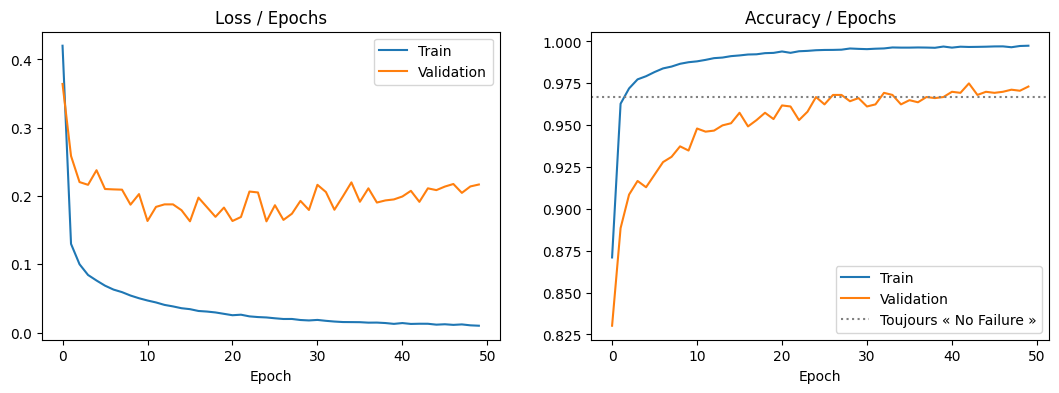

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(hist["tr_loss"], label="Train")
axes[0].plot(hist["va_loss"], label="Validation")
axes[0].set_title("Loss / Epochs")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(hist["tr_acc"], label="Train")
axes[1].plot(hist["va_acc"], label="Validation")
axes[1].axhline(1543 / 1596, color="gray", linestyle=":", label="Toujours « No Failure »")
axes[1].set_title("Accuracy / Epochs")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.show()

**Courbes Loss / Accuracy (modèle de base, 50 epochs) :**
- La loss de train décroît régulièrement ; celle de validation chute en quelques epochs vers ≈ 0,2 puis oscille (≈ 0,16-0,22) sans s'améliorer, alors que l'écart avec le train grandit : surapprentissage.
- L'accuracy de validation reste sous celle d'un modèle répondant toujours « No Failure » (96,7 %) jusqu'à l'epoch ≈ 26, et ne la dépasse durablement qu'à partir de l'epoch ≈ 40, de moins d'un point.
- Les deux accuracies ne sont pas comparables : le train est équilibré (SMOTE), la validation reflète la répartition réelle.
- Les courbes sont bruitées : la validation ne contient que 53 pannes. Conséquence : early stopping et régularisation.

In [61]:
# GridSearch
from sklearn.metrics import f1_score

def train_clf(hidden=(64, 32), lr=0.001, epochs=20, opt_name="adam"):
    torch.manual_seed(42)
    layers, prev = [], 11
    for h in hidden:
        layers += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    layers.append(nn.Linear(prev, 5))
    model = nn.Sequential(*layers)

    criterion = nn.CrossEntropyLoss()
    if opt_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    loader = DataLoader(TensorDataset(X_tr_c, y_tr_c), batch_size=64, shuffle=True)
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        pred = model(X_va_c).argmax(dim=1).numpy()
    return f1_score(y_val, pred, average="macro", zero_division=0)

print(train_clf())
print(train_clf(hidden=(16,), epochs=10))

0.6352475247524753
0.5009698197271175


**Critère de sélection du GridSearch : F1 macro sur la validation.**
L'accuracy est inutilisable (96,7 % pour un modèle qui répond toujours « No Failure »). Le F1 macro (moyenne des F1 de chaque classe) pénalise une classe ratée. Référence à battre : 0,704 (réseau 64-32, Adam, 50 epochs).
Limite : la validation ne contient que 7 à 18 exemples par type de panne, donc les écarts faibles entre configurations ne sont pas significatifs.

In [62]:
from sklearn.model_selection import ParameterGrid

grid = {
    "hidden": [(64, 32), (128, 64)],
    "lr": [0.001, 0.0001],
    "epochs": [20, 50],
    "opt_name": ["adam", "sgd"],
}

results = []
for params in ParameterGrid(grid):
    results.append({**params, "f1_macro": train_clf(**params)})

res_c = pd.DataFrame(results).sort_values("f1_macro", ascending=False)
print(res_c.to_string(index=False))

 epochs    hidden     lr opt_name  f1_macro
     50  (64, 32) 0.0010     adam  0.704449
     50 (128, 64) 0.0010     adam  0.701285
     20 (128, 64) 0.0010     adam  0.700979
     20  (64, 32) 0.0010     adam  0.635248
     50 (128, 64) 0.0001     adam  0.623149
     50  (64, 32) 0.0001     adam  0.584251
     20 (128, 64) 0.0001     adam  0.566275
     20  (64, 32) 0.0001     adam  0.503677
     50  (64, 32) 0.0010      sgd  0.400107
     50 (128, 64) 0.0010      sgd  0.398833
     20 (128, 64) 0.0010      sgd  0.312602
     20  (64, 32) 0.0010      sgd  0.295537
     50  (64, 32) 0.0001      sgd  0.084974
     20  (64, 32) 0.0001      sgd  0.075507
     50 (128, 64) 0.0001      sgd  0.060092
     20 (128, 64) 0.0001      sgd  0.057643


**Résultats du GridSearch (16 combinaisons, critère : F1 macro sur la validation) :**
- Grille : architecture {(64,32), (128,64)}, learning rate {1e-3, 1e-4}, epochs {20, 50}, optimiseur {Adam, SGD}.
- Meilleure configuration : (64,32), lr = 1e-3, Adam, 50 epochs → F1 macro = 0,704. C'est le modèle de base : le GridSearch n'apporte pas d'amélioration, mais il écarte SGD (≤ 0,40) et lr = 1e-4.
- Les trois premières configurations (0,704 / 0,701 / 0,701) sont indiscernables compte tenu du bruit (7 à 18 exemples par panne en validation) ; on retient la plus simple.
- Avec un petit learning rate, plus d'epochs améliorent le score ; le meilleur résultat est au bord de la grille (50 epochs), l'early stopping explorera plus loin.

# Régularisation

In [63]:
# on commence par l'early stopping
import copy

def fit_es(model, weight_decay=0.0, max_epochs=100, patience=15, lr=0.001):
    torch.manual_seed(42)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(X_tr_c, y_tr_c), batch_size=64, shuffle=True)

    best_f1, best_state, wait, hist = -1, None, 0, []
    for epoch in range(max_epochs):
        model.train()
        for xb, yb in loader:
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            pred = model(X_va_c).argmax(dim=1).numpy()
        f1 = f1_score(y_val, pred, average="macro", zero_division=0)
        hist.append(f1)

        if f1 > best_f1:
            best_f1, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return best_f1, int(np.argmax(hist)) + 1, len(hist)

torch.manual_seed(42)
model_es_c = MLPClf()
f1_es, best_ep, stop_ep = fit_es(model_es_c)
print("F1 macro (validation) :", round(f1_es, 4))
print("Meilleur epoch :", best_ep, "| arrêt à l'epoch :", stop_ep)

F1 macro (validation) : 0.7258
Meilleur epoch : 44 | arrêt à l'epoch : 59


**Régularisation 1 : Early stopping (critère : F1 macro de validation, patience = 15) :**
- Meilleur epoch : 44 (F1 macro = 0,7258), arrêt à l'epoch 59 ; les poids de l'epoch 44 sont restaurés.
- Gain de ≈ 0,02 sur le modèle de base (0,704), du même ordre que l'effet d'un seul exemple de Tool Wear en validation : amélioration non démontrée.
- Ce score est un maximum sur une courbe bruitée, et la validation a déjà servi à choisir les hyperparamètres : il est légèrement optimiste. Le test donnera l'évaluation finale.

In [64]:
# Régularisation 2 et 3 : Dropout et L2
class MLPClfDropout(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(11, 64), nn.ReLU(), nn.Dropout(p),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(p),
            nn.Linear(32, 5)
        )

    def forward(self, x):
        return self.net(x)

# Dropout (p = 0,3) + early stopping
torch.manual_seed(42)
model_do_c = MLPClfDropout(p=0.3)
f1_do, ep_do, stop_do = fit_es(model_do_c)
print("Dropout | F1 macro :", round(f1_do, 4), "| meilleur epoch :", ep_do, "| arrêt :", stop_do)

# L2 (weight decay = 1e-2) + early stopping
torch.manual_seed(42)
model_l2_c = MLPClf()
f1_l2, ep_l2, stop_l2 = fit_es(model_l2_c, weight_decay=1e-2)
print("L2      | F1 macro :", round(f1_l2, 4), "| meilleur epoch :", ep_l2, "| arrêt :", stop_l2)

Dropout | F1 macro : 0.6855 | meilleur epoch : 58 | arrêt : 73
L2      | F1 macro : 0.4698 | meilleur epoch : 21 | arrêt : 36


**Régularisation 2 : Dropout (p = 0,3) + early stopping :**
- F1 macro de validation = 0,6855 (meilleur epoch 58), contre 0,7258 pour l'early stopping seul : pas d'amélioration (écart de l'ordre d'un ou deux exemples de Tool Wear, donc non concluant). Hypothèse : les étiquettes suivent des règles nettes, que le bruit du dropout ne facilite pas.

**Régularisation 3 : L2 (weight decay = 1e-2) + early stopping :**
- F1 macro de validation = 0,4698 : forte dégradation. Hypothèse : pénalité trop forte, qui contraint les poids et empêche de séparer les classes rares. Des valeurs plus faibles sont testées ci-dessous.

In [65]:
# un petit test de force pour L2
for wd in [1e-4, 1e-3]:
    torch.manual_seed(42)
    m = MLPClf()
    f1, ep, stop = fit_es(m, weight_decay=wd)
    print(f"L2 wd={wd} | F1 macro : {f1:.4f} | meilleur epoch : {ep} | arrêt : {stop}")

L2 wd=0.0001 | F1 macro : 0.7224 | meilleur epoch : 57 | arrêt : 72
L2 wd=0.001 | F1 macro : 0.6490 | meilleur epoch : 42 | arrêt : 57


**Régularisation 3 (suite) : L2 selon la force de la pénalité :**
- weight decay = 1e-4 : F1 macro = 0,7224 (équivalent à l'early stopping seul) ; 1e-3 : 0,6490 ; 1e-2 : 0,4698. La dégradation croît avec la pénalité : hypothèse, les classes rares exigent des poids assez grands pour des frontières nettes, qu'une pénalité forte écrase.

**Comparaison des techniques de régularisation (F1 macro, validation) :**
| Modèle | F1 macro |
|---|---|
| Base, 50 epochs | 0,7044 |
| + Early stopping (patience 15) | 0,7258 |
| + Dropout (0,3) | 0,6855 |
| + L2 (1e-4 / 1e-3 / 1e-2) | 0,7224 / 0,6490 / 0,4698 |

- L'early stopping seul, la technique la plus simple, est retenu : les écarts avec le modèle de base ou le L2 faible sont du même ordre que le bruit de la validation (53 pannes).
- Le dropout et un L2 fort dégradent le score.

In [66]:
X_tr_real = torch.tensor(X_tr.values, dtype=torch.float32)

model_es_c.eval()
with torch.no_grad():
    pred_tr = model_es_c(X_tr_real).argmax(dim=1).numpy()
    pred_te = model_es_c(X_te_c).argmax(dim=1).numpy()

print("=== TRAIN (lignes réelles, non rééquilibrées) ===")
print(classification_report(y_tr, pred_tr, target_names=classes, digits=3, zero_division=0))
print("=== TEST ===")
print(classification_report(y_test, pred_te, target_names=classes, digits=3, zero_division=0))
print(confusion_matrix(y_test, pred_te))

=== TRAIN (lignes réelles, non rééquilibrées) ===
                          precision    recall  f1-score   support

              No Failure      1.000     0.990     0.995      6171
Heat Dissipation Failure      0.935     1.000     0.966        72
           Power Failure      0.910     1.000     0.953        61
      Overstrain Failure      0.803     1.000     0.891        49
       Tool Wear Failure      0.439     1.000     0.611        29

                accuracy                          0.991      6382
               macro avg      0.818     0.998     0.883      6382
            weighted avg      0.994     0.991     0.992      6382

=== TEST ===
                          precision    recall  f1-score   support

              No Failure      0.994     0.979     0.987      1929
Heat Dissipation Failure      0.559     0.864     0.679        22
           Power Failure      0.783     0.947     0.857        19
      Overstrain Failure      0.667     0.875     0.757        16
       To

**Évaluation finale (modèle retenu : MLP 64-32, early stopping sur le F1 macro) :**
- Test : accuracy = 97,3 % (96,7 % pour un modèle répondant toujours « No Failure ») ; F1 macro = 0,687, contre 0,726 en validation (score de validation légèrement optimiste).
- Heat Dissipation, Power et Overstrain sont bien détectées (sensibilité 0,86-0,95), avec des fausses alarmes (précision 0,56-0,78).
- Tool Wear Failure est très mal détectée (sensibilité 0,22, précision 0,12) : classe mélangée aux machines saines dans l'EDA, et 99 % de ses exemples d'entraînement sont synthétiques.
- 11 pannes sur 66 ne sont pas détectées et 40 machines saines sur 1929 (2,1 %) déclenchent une fausse alarme.
- Train (lignes réelles) : sensibilité de 1,000 sur toutes les pannes, F1 macro 0,883 ; l'écart avec le test indique du surapprentissage. Avec 9 à 22 exemples par panne en test, les scores par classe sont très instables.

# Synthèse finale

Durant ce premier Lab du module Deep Learning et Applications, j'ai appliqué les premières notions vues en séances sur deux problèmes différents : une **régression** (prédire la variation du prix de l'action AAPL) et une **classification multi-classes** (prédire le type de panne de machines). J'ai commencé par revoir le nettoyage des données, le preprocessing et l'EDA, puis j'ai pratiqué PyTorch pour construire un MLP pour chaque problème, en suivant la boucle d'entraînement vue en cours : forward → loss → backward → step, avec `MSELoss` en régression et `CrossEntropyLoss` en classification.

**Ce que j'ai retenu de la régression.** Pour une série temporelle, le découpage doit se faire par date, sinon il y a fuite de données (data leakage). Le prix d'une action étant non stationnaire, prédire son niveau obligeait aussi le modèle à extrapoler hors de la plage d'entraînement. Mon premier modèle apprenait très vite parce que close(t) est presque égal à close(t+1) : c'est pourquoi il faut toujours comparer à un modèle naïf (« demain = aujourd'hui »). En prédisant le rendement du lendemain, le problème est devenu honnête, et le MLP fait à peine mieux que le naïf (MAE de 1,041 $ contre 1,047 $).

**Ce que j'ai retenu de la classification.** Les classes sont très déséquilibrées : un modèle qui répond toujours « No Failure » a 96,7 % d'accuracy. L'accuracy est donc trompeuse ; j'ai utilisé la précision, la sensibilité et le F1 par classe, avec le F1 macro comme critère de choix. J'ai rééquilibré le train avec SMOTE, uniquement après le découpage, pour éviter la fuite de données. Résultat : les pannes sont mieux détectées, au prix de fausses alarmes, et Tool Wear reste mal détectée (sensibilité de 0,22 sur 9 exemples).

**Surapprentissage et choix des hyperparamètres.** Pour le surapprentissage (vu lors de la dernière séance), j'ai lu les courbes (la loss de validation remonte alors que celle du train baisse) et appliqué l'early stopping, le dropout et le L2. L'early stopping a été utile en régression ; en classification, les gains sont restés dans le bruit, et un L2 trop fort a fait chuter le F1 macro de 0,73 à 0,47. Les hyperparamètres ont été choisis par GridSearch sur un jeu de validation, et le test n'a servi qu'à l'évaluation finale.

**Limites.** Un seul entraînement par configuration et peu d'exemples par panne (9 à 22 en test) : les petits écarts entre modèles sont du bruit. Les étiquettes du dataset semblent aussi issues de règles à seuils, donc les scores ne reflètent pas forcément un cas réel.